# Inleiding

De effectieve strijklengte wordt in HB Havens bepaald als de maximum strijklengte binnen de windrichting. Dit sluit niet aan bij gangbare 
definities en geeft mogelijk grillige resultaten. 

Voorgestelde oplossing:
- Cosinus weging over sector

# Imports

In [5]:
import sys
import os
import shutil
# import copy
import matplotlib.pyplot as plt
import pandas as pd 
import numpy as np

owd = os.getcwd()
testdir = os.path.dirname(owd)
sys.path.append(testdir)
trunkdir = os.path.dirname(testdir)
sys.path.append(trunkdir)

import common
from hbhavens.core.models import MainModel
from hbhavens.core.geometry import extend_point_to_linestring

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

# Schematisatie

In [6]:
case = 'urk'
datadir = os.path.join(trunkdir, 'tests', 'data', case)
paths = {
    'harborarea': os.path.join(datadir, 'shapes', 'haventerrein.shp'),
    'breakwater': os.path.join(datadir, 'shapes', 'havendammen.shp'),
    'result_locations': os.path.join(datadir, 'shapes', 'uitvoerlocaties.shp'),
    'hrd': os.path.join(datadir, 'databases', 'WBI2017_IJsselmeer_7-2_v02_steunpunt.sqlite'),
    'config': os.path.join(datadir, 'databases', 'WBI2017_IJsselmeer_7-2_v02_steunpunt.config.sqlite'),
    'hlcd': os.path.join(datadir, '..', 'hlcd.sqlite'),
}
trajecten = ['7-2']
bedlevel = -5.0
supportlocation = 'YM_3_7-2_ha02_00001'

# Create and run for various combinations of processes

In [7]:
tempdir = os.path.join(os.path.dirname(trunkdir),'temp')

In [8]:
model = MainModel()
model.project.settings['project']['name'] = case
model.project.settings['project']['user']['email'] = 'benit@hkv.nl'
model.project.settings['project']['user']['name'] = 'Matthijs Bénit'
model.project.save_as(os.path.join(tempdir, case, case + '.json'))

common.add_schematisation(model, paths=paths, supportlocationname=supportlocation, trajecten=trajecten, bedlevel=bedlevel)

# Calculate wave processes
model.simple_calculation.run_all(['Lokale golfgroei'])
model.simple_calculation.combinedresults.run(['Lokale golfgroei'])
model.simple_calculation.mainmodel.project.settings['simple']['finished'] = True
model.simple_calculation.save_results()

# Save results
model.project.save()
model.save_tables()

#print(vars(model))

In [9]:
model.simple_calculation.wavegrowth.output

Wind direction  Wind speed  Water level  U10  \
Location  HydraulicLoadId                                                 
7-2_00001 20                        225.0         0.0         -0.4  0.0   
          72                        225.0         0.0         -0.1  0.0   
          124                       225.0         0.0          0.4  0.0   
          176                       225.0         0.0          1.0  0.0   
          228                       225.0         0.0          1.8  0.0   
...                                   ...         ...          ...  ...   
7-2_00016 203895                    360.0         0.0         -0.4  0.0   
          203896                    360.0         0.0         -0.1  0.0   
          203897                    360.0         0.0          0.4  0.0   
          203898                    360.0         0.0          1.0  0.0   
          203899                    360.0         0.0          1.8  0.0   

                                 Feq  Feqdir  Terrain level  Water depth  \
Location  HydraulicLoadId                                                  
7-2_00001 20               23.124064   225.0      -5.000000     4.600000   
          72               23.124064   225.0      -5.000000     4.900000   
          124              23.124064   225.0      -5.000000     5.400000   
          176              23.124064   225.0      -5.000000     6.000000   
          228              23.124064   225.0      -5.000000     6.800000   
...                              ...     ...            ...          ...   
7-2_00016 203895           35.017606     0.0      -0.926221     0.526221   
          203896           35.017606     0.0      -0.926221     0.826221   
          203897           35.017606     0.0      -0.926221     1.326221   
          203898           35.017606     0.0      -0.926221     1.926221   
          203899           35.017606     0.0      -0.926221     2.726221   

                           Hs,lg  Elg  
Location  HydraulicLoadId              
7-2_00001 20                 0.0  0.0  
          72                 0.0  0.0  
          124                0.0  0.0  
          176                0.0  0.0  
          228                0.0  0.0  
...                          ...  ...  
7-2_00016 203895             0.0  0.0  
          203896             0.0  0.0  
          203897             0.0  0.0  
          203898             0.0  0.0  
          203899             0.0  0.0  

[12800 rows x 10 columns]

In [10]:
model.simple_calculation.wavegrowth.output.to_csv('wavegrowth_results_urk_BU', sep=";", decimal=".", compression='gzip')

# Manually reproduce results

In [11]:
table_path = os.path.join(trunkdir,'tests', "data", "urk",'simple', 'wavegrowth_results_urk_BU.gz')
old = pd.read_csv(table_path, sep=";", decimal=".")
new = model.simple_calculation.wavegrowth.output.reset_index()

In [12]:
locations = old['Location'].unique()
location = locations[2]
iloc = model.schematisation.result_locations.loc[model.schematisation.result_locations['Naam'] ==  location].index[0]
location, iloc

('7-2_00003', 2)

# Two hydraulic conditions for one location

In [13]:
# Wind direction 225 and 270 degrees with a wind speed of 42 m/s and water level of 1.8m
hydraulicloadid = model.hydraulic_loads.loc[(model.hydraulic_loads['Wind direction'] == 270.) & (model.hydraulic_loads['Wind speed'] == 42.) & (model.hydraulic_loads['Water level IJssel lake'] == 1.8) | (model.hydraulic_loads['Wind direction'] == 225.) & (model.hydraulic_loads['Wind speed'] == 42.) & (model.hydraulic_loads['Water level IJssel lake'] == 1.8)].index#[0]
hydraulicloadid
model.hydraulic_loads.loc[hydraulicloadid]

Index([23628, 28308], dtype='int64', name='HydraulicLoadId')

,ClosingSituationId,Wind direction,Water level IJssel lake,Wind speed,h,Hs,Tp,"Tm-1,0",Wave direction,Description
HydraulicLoadId,,,,,,,,,,
23628,1,225.0,1.8,42.0,4.110,2.815,5.81,5.1121,247.15,D=225.0 M=1.80 U=42
28308,1,270.0,1.8,42.0,4.291,3.139,6.68,5.5808,261.58,D=270.0 M=1.80 U=42


In [14]:
iold = old.loc[(old['Location'] == location) & (old['HydraulicLoadId'] == hydraulicloadid[0]) | (old['Location'] == location) & (old['HydraulicLoadId'] == hydraulicloadid[1]) ].index
old.iloc[iold]

,Location,HydraulicLoadId,Wind direction,Wind speed,Water level,U10,Feq,maxdir,Terrain level,Water depth,"Hs,lg",Elg
2054,7-2_00003,23628,225.0,42.0,4.110,43.3,386.998290,238.0,-4.526054,8.636054,0.878745,0.048262
2144,7-2_00003,28308,270.0,42.0,4.291,43.3,703.801675,288.0,-1.404126,5.695126,1.057273,0.069864


In [15]:
inew = new.loc[(new['Location'] == location) & (new['HydraulicLoadId'] == hydraulicloadid[0]) | (new['Location'] == location) & (new['HydraulicLoadId'] == hydraulicloadid[1])].index
new.iloc[inew]

,Location,HydraulicLoadId,Wind direction,Wind speed,Water level,U10,Feq,Feqdir,Terrain level,Water depth,"Hs,lg",Elg
2054,7-2_00003,23628,225.0,42.0,4.110,40.02,244.645355,225.0,-4.526076,8.636076,0.670154,0.028069
2144,7-2_00003,28308,270.0,42.0,4.291,40.02,445.938934,270.0,-1.404269,5.695269,0.826705,0.042715


# Visualisation of the fetches for both hydraulic conditions for the old and new method

In [16]:
model.schematisation.result_locations.iloc[iloc]

Naam                                            7-2_00003
Normaal                                        268.420522
geometry    POINT (169552.12483996764 519074.42908274085)
Name: 2, dtype: object

In [17]:
old.iloc[iold]['maxdir'].values[0]

238.0

In [18]:
new

,Location,HydraulicLoadId,Wind direction,Wind speed,Water level,U10,Feq,Feqdir,Terrain level,Water depth,"Hs,lg",Elg
0,7-2_00001,20,225.0,0.0,-0.4,0.0,23.124064,225.0,-5.000000,4.600000,0.0,0.0
1,7-2_00001,72,225.0,0.0,-0.1,0.0,23.124064,225.0,-5.000000,4.900000,0.0,0.0
2,7-2_00001,124,225.0,0.0,0.4,0.0,23.124064,225.0,-5.000000,5.400000,0.0,0.0
3,7-2_00001,176,225.0,0.0,1.0,0.0,23.124064,225.0,-5.000000,6.000000,0.0,0.0
4,7-2_00001,228,225.0,0.0,1.8,0.0,23.124064,225.0,-5.000000,6.800000,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
12795,7-2_00016,203895,360.0,0.0,-0.4,0.0,35.017606,0.0,-0.926221,0.526221,0.0,0.0
12796,7-2_00016,203896,360.0,0.0,-0.1,0.0,35.017606,0.0,-0.926221,0.826221,0.0,0.0
12797,7-2_00016,203897,360.0,0.0,0.4,0.0,35.017606,0.0,-0.926221,1.326221,0.0,0.0
12798,7-2_00016,203898,360.0,0.0,1.0,0.0,35.017606,0.0,-0.926221,1.926221,0.0,0.0


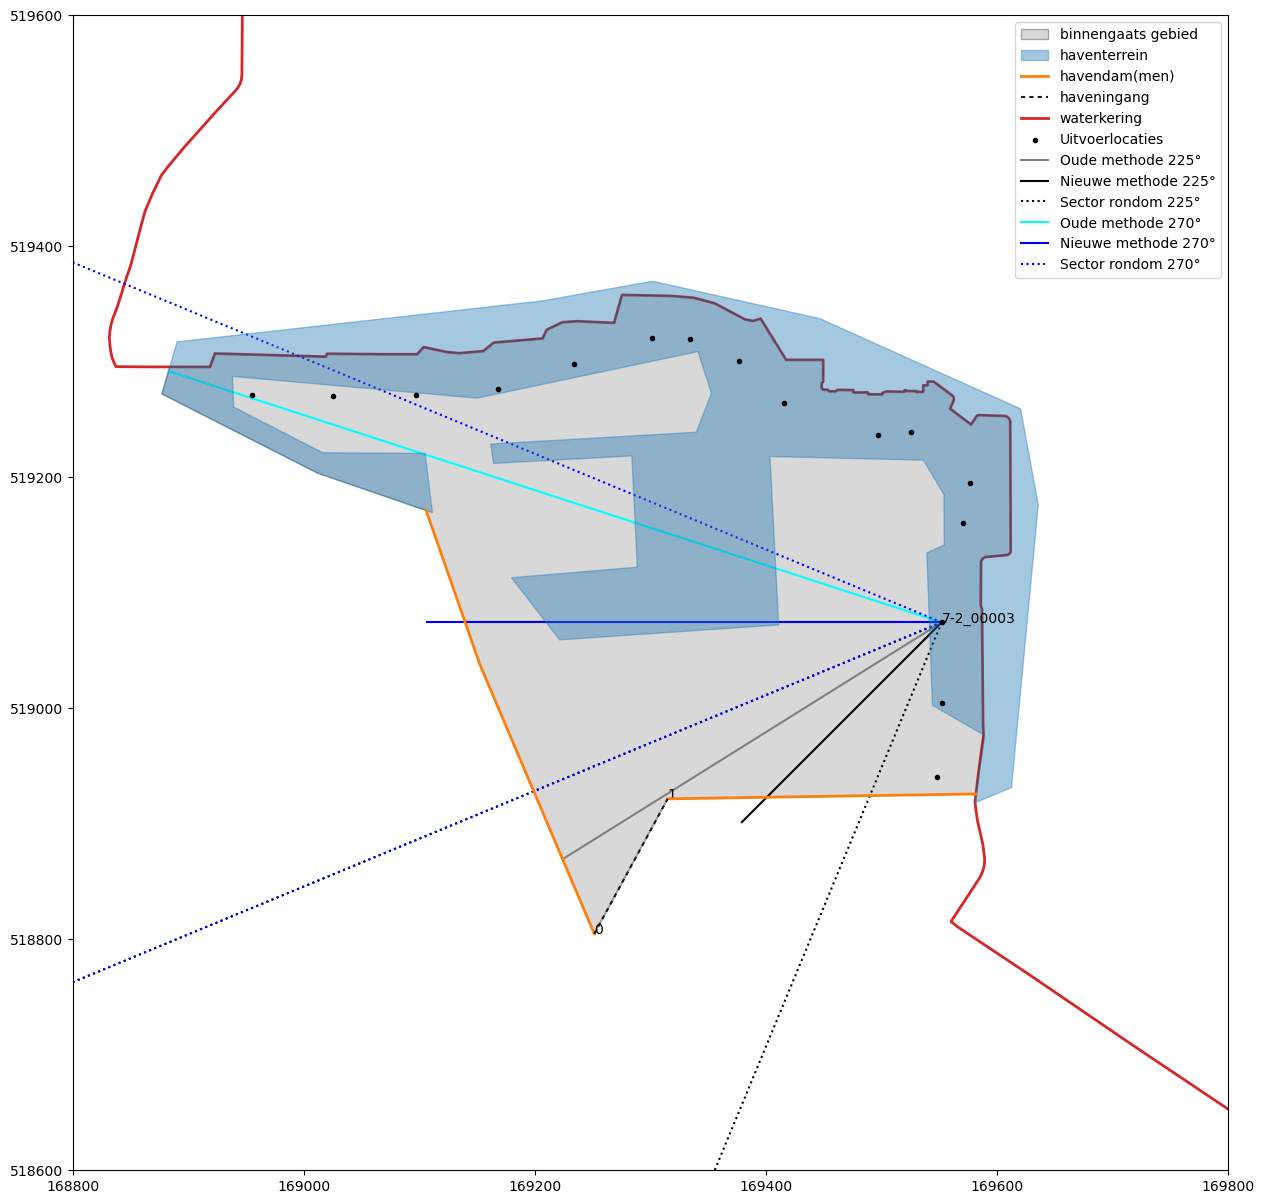

In [19]:
# plot schematisation and fetch of selected (old) result
fig, ax = model.schematisation.plot_schematisation(buffer=10,locations=False)
_ = model.schematisation.result_locations.plot(ax=ax, color='k', marker='.', zorder=10, label='Uitvoerlocaties')

loc = model.schematisation.result_locations.iloc[iloc]
_ = ax.text(loc['geometry'].coords[0][0], loc['geometry'].coords[0][1], loc['Naam'])

# Dit zijn de strijklengtes met oude en nieuwe methodes 
oldline = extend_point_to_linestring(model.schematisation.result_locations.iloc[iloc]['geometry'], old.iloc[iold]['maxdir'].values[0], (0, -old.iloc[iold]['Feq'].values[0]))
newline = extend_point_to_linestring(model.schematisation.result_locations.iloc[iloc]['geometry'], new.iloc[iold]['Feqdir'].values[0], (0, -new.iloc[iold]['Feq'].values[0]))
sectorlow = extend_point_to_linestring(model.schematisation.result_locations.iloc[iloc]['geometry'], new.iloc[iold]['Feqdir'].values[0] - model.simple_calculation.wavegrowth.spread_angle/2, (0, -1000))
sectorhigh = extend_point_to_linestring(model.schematisation.result_locations.iloc[iloc]['geometry'], new.iloc[iold]['Feqdir'].values[0] + model.simple_calculation.wavegrowth.spread_angle/2, (0, -1000))
_ = ax.plot(oldline[:,0],oldline[:,1],'grey',label='Oude methode 225°')
_ = ax.plot(newline[:,0],newline[:,1],'black',label='Nieuwe methode 225°')
_ = ax.plot(sectorlow[:,0],sectorlow[:,1],'black',ls=':',label='Sector rondom 225°')
_ = ax.plot(sectorhigh[:,0],sectorhigh[:,1],'black',ls=':')

oldline = extend_point_to_linestring(model.schematisation.result_locations.iloc[iloc]['geometry'], old.iloc[iold]['maxdir'].values[1], (0, -old.iloc[iold]['Feq'].values[1]))
newline = extend_point_to_linestring(model.schematisation.result_locations.iloc[iloc]['geometry'], new.iloc[iold]['Feqdir'].values[1], (0, -new.iloc[iold]['Feq'].values[1]))
sectorlow = extend_point_to_linestring(model.schematisation.result_locations.iloc[iloc]['geometry'], new.iloc[iold]['Feqdir'].values[1] - model.simple_calculation.wavegrowth.spread_angle/2, (0, -1000))
sectorhigh = extend_point_to_linestring(model.schematisation.result_locations.iloc[iloc]['geometry'], new.iloc[iold]['Feqdir'].values[1] + model.simple_calculation.wavegrowth.spread_angle/2, (0, -1000))
_ = ax.plot(oldline[:,0],oldline[:,1],'cyan',label='Oude methode 270°')
_ = ax.plot(newline[:,0],newline[:,1],'blue',label='Nieuwe methode 270°')
_ = ax.plot(sectorlow[:,0],sectorlow[:,1],'blue',ls=':',label='Sector rondom 270°')
_ = ax.plot(sectorhigh[:,0],sectorhigh[:,1],'blue',ls=':')

_ = ax.legend(loc='upper right')
_ = ax.set_xlim(xmin=168800,xmax=169800, auto=True)
_ = ax.set_ylim(ymin=518600,ymax=519600, auto=True)

,ClosingSituationId,Wind direction,Water level IJssel lake,Wind speed,h,Hs,Tp,"Tm-1,0",Wave direction,Description
HydraulicLoadId,,,,,,,,,,
2568,1,22.5,1.8,42.0,1.822,1.165,2.84,2.6487,5.45,D=022.5 M=1.80 U=42
4908,1,45.0,1.8,42.0,1.842,1.138,2.80,2.5833,46.11,D=045.0 M=1.80 U=42
7248,1,67.5,1.8,42.0,1.861,1.216,2.84,2.7359,86.48,D=067.5 M=1.80 U=42
9588,1,90.0,1.8,42.0,1.871,1.316,3.18,2.8885,107.20,D=090.0 M=1.80 U=42
11928,1,112.5,1.8,42.0,1.876,1.390,3.33,2.9757,122.02,D=112.5 M=1.80 U=42
14268,1,135.0,1.8,42.0,1.876,1.383,3.21,2.9648,138.24,D=135.0 M=1.80 U=42
16608,1,157.5,1.8,42.0,1.872,1.385,3.17,2.9430,158.57,D=157.5 M=1.80 U=42
18948,1,180.0,1.8,42.0,3.018,1.733,3.33,3.5425,202.50,D=180.0 M=1.80 U=42
21288,1,202.5,1.8,42.0,3.684,2.328,5.19,4.4908,235.20,D=202.5 M=1.80 U=42


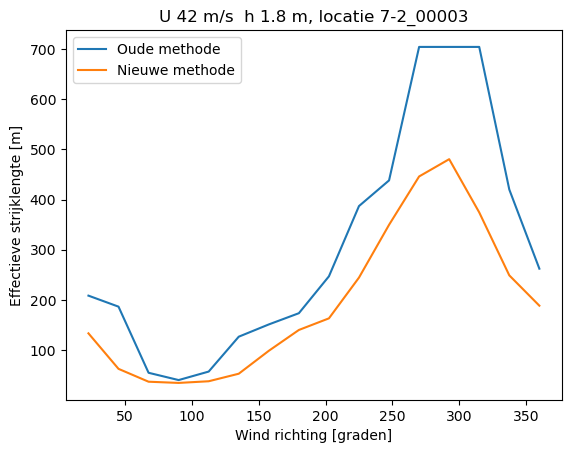

In [20]:
hydraulicloadid = model.hydraulic_loads.loc[(model.hydraulic_loads['Wind speed'] == 42.) & (model.hydraulic_loads['Water level IJssel lake'] == 1.8)].index#[0]
model.hydraulic_loads.loc[hydraulicloadid]

#iold = old.loc[(old['Location'] == location) & (old['HydraulicLoadId'] == hydraulicloadid)].index
iold = old.loc[(old['Location'] == location) & (old['HydraulicLoadId'].isin(hydraulicloadid))].index
_ = plt.plot(old['Wind direction'].iloc[iold].values,old['Feq'].iloc[iold].values,label='Oude methode')

inew = new.loc[(new['Location'] == location) & (new['HydraulicLoadId'].isin(hydraulicloadid))].index
_ = plt.plot(new['Wind direction'].iloc[iold].values,new['Feq'].iloc[iold].values,label='Nieuwe methode')

_ = plt.legend()
_ = plt.xlabel('Wind richting [graden]')
_ = plt.ylabel('Effectieve strijklengte [m]')
_ = plt.title('U 42 m/s  h 1.8 m, locatie 7-2_00003')